<a href="https://colab.research.google.com/github/S3rcho/C-digos-de-Colab/blob/Laboratorios-Google-Colab/Proyecto_Hojas_de_Seguridad%3B_Jara%2C_Sergio%2C_Brandon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Importación de Librerias necesarias:
import pandas as pd
import numpy as np
import re

#Lectura de "hojas_seguridad.xlsx" (Excel) y conversión DataFrame:
df = pd.read_excel("hojas_seguridad.xlsx")


#Corrección de expresiones numéricas para lectura en Pyhton:
def limpiar_numero(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).replace(",", ".")
    match = re.search(r"(-?[\d\.]+)", val_str)
    if match:
        try:
            return float(match.group(1))
        except:
            return np.nan
    return np.nan
#Columnas con correcciones de expresiones numéricas y redefinición con "def":
df["Masa_Num"] = df["Masa Molar"].apply(limpiar_numero)
df["Fusion_Num"] = df["Punto de fusión"].apply(limpiar_numero)


#Confirmación/Demostración inicial DataFrame:
print("=====================================")
print("--- Información Inicial DataFrame ---")
print("=====================================")
print(df.head())

#Demostración de información de columnas DataFrame con ".shape[1]"¨:
print("===================================")
print("----- Información de Columnas -----")
print("===================================")
print("Número total de columnas:", df.shape[1])
print("Nombres de las columnas:", df.columns.tolist())

#Demostrar información/nombres de la columna "Nombre" DataFrame:
print("===================================")
print("------ Nombres de Compuestos ------")
print("===================================")
print(df["Nombre"])

#Demostración "Nombre", "Fórmula", "Masa Molar" de los compuestos con Masa Molar(g/mol) < 100:
print("==============================================")
print("--- Compuestos con Masa Molar(g/mol) < 100 ---")
print("==============================================")
menor_100 = df[df["Masa_Num"] < 100]
print(menor_100[["Nombre", "Fórmula", "Masa Molar"]])

#Demostración "Nombre", "Fórmula", "Masa Molar" de los 10 compuestos con mayor Masa Molar(g/mol):
print("==========================================")
print("--- 10 Compuestos con mayor Masa Molar ---")
print("==========================================")
top_mayor_masa = df.sort_values(by='Masa_Num', ascending=False).head(10)
print(top_mayor_masa[["Nombre", "Fórmula", "Masa Molar"]])

#Demostración "Nombre", "Fórmula", "Punto de fusión" de los 10 compuestos con menor Punto de Fusión:
print("===============================================")
print("--- 10 Compuestos con menor Punto de Fusión ---")
print("===============================================")
top_menor_fusion = df.sort_values(by='Fusion_Num', ascending=True).head(10)
print(top_menor_fusion[["Nombre", "Fórmula", "Punto de fusión"]])


#Función para filtrar información de un Compuesto buscado:
def buscar_compuesto(df, nombre_compuesto):
    resultado = df[df["Nombre"].str.contains(nombre_compuesto, case=False, na=False)]
    if not resultado.empty:
        return resultado
    else:
        return "El compuesto no se encuentra registrado en la tabla."
#Demostración busqueda información de Compuesto Químico:
print("======================================================")
print("------- Busqueda Información Compuesto Químico -------")
print("======================================================")
compuesto_buscado = input("Agregue Compuesto Químico: ")
print("======================================================")
print(buscar_compuesto(df, compuesto_buscado))

--- Información Inicial DataFrame ---
   A                           Nombre    Fórmula     Masa Molar  \
0  1      Cloruro de aluminio anhidro      AlCl₃  133,34 g/mol.   
1  2                    Azul de timol  C₂₇H₃₀O₅S  466,59 g/mol.   
2  3                   Dietilenglicol    C₄H₁₀O₃   106,12 g/mol   
3  4                       Cloroformo      CHCl₃   119,38 g/mol   
4  5  Agar Xilosa Lisina Desoxicolato        ---           ---.   

                                Punto de fusión Punto de ebullición  \
0                                      187,7 °C           192,6 º C   
1                                          ---.         221-224 °C.   
2                                  242 – 252 °C              6,5 °C   
3  disolvente orgánico. Tipo AX Marrón conforme             64 º C.   
4                                          ---.                ---.   

                      Inflamabilidad  \
0                                NaN   
1                                NaN   
2  138 °C a 

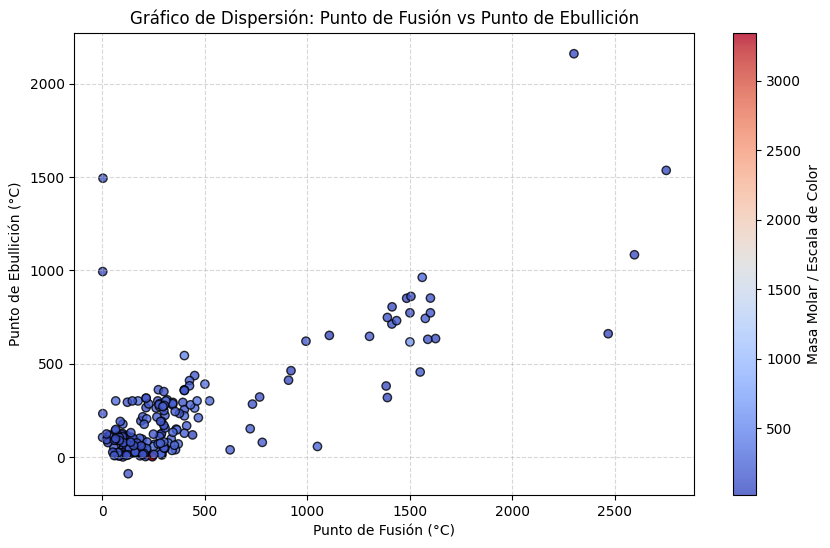

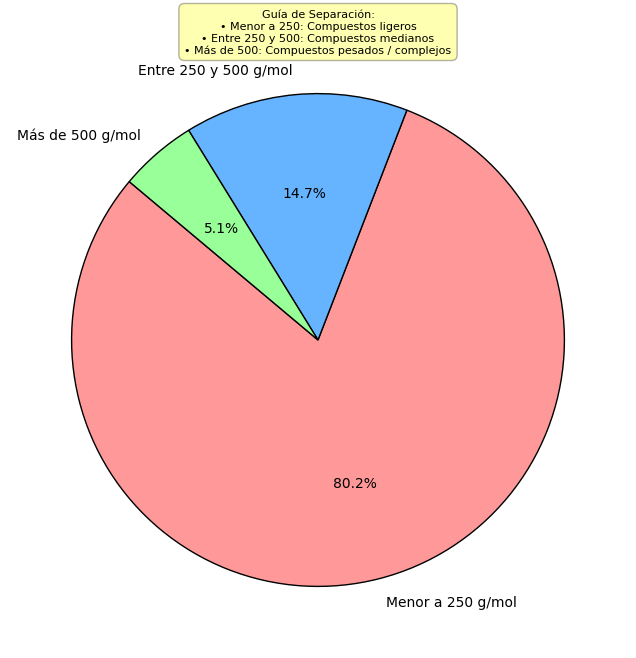

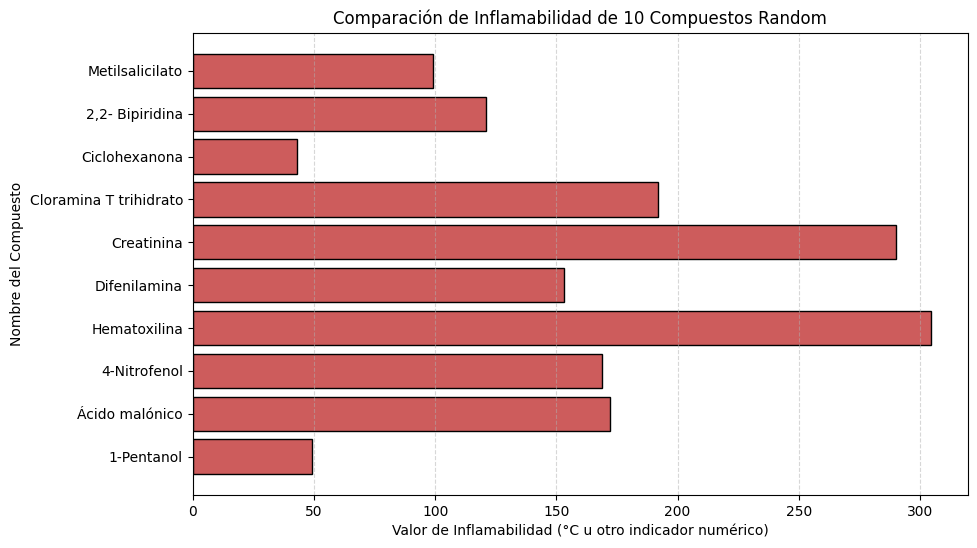

In [ ]:
#Importación de Librerias necesarias (algunas cargadas anteriormente):
import matplotlib.pyplot as plt


#Corrección de expresiones numéricas para lectura en Pyhton:
def limpiar_numero_graficos(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).replace(",", ".")
    match = re.search(r"(-?[\d\.]+)", val_str)
    if match:
        try:
            return float(match.group(1))
        except:
            return np.nan
    return np.nan
#Columnas con correcciones de expresiones numéricas y redefinición con "def":
df['Masa_Num'] = df['Masa Molar'].apply(limpiar_numero_graficos)
df['Punto_Fusion_Num'] = df['Punto de fusión'].apply(limpiar_numero_graficos)
df['Punto_Ebullicion_Num'] = df['Punto de ebullición'].apply(limpiar_numero_graficos)
df['Inflamabilidad_Num'] = df['Inflamabilidad'].apply(limpiar_numero_graficos)


#Gráfico de Dispersión; Comparando Punto de Fusión y Punto de Ebullición (más barra de Masa Molar):

#Establecimiento de Dimensiones
plt.figure(figsize=(10, 6))
#Filtrado de Valores Innecesarios y Listado de Necesarios
df_disp = df.dropna(subset=['Punto_Fusion_Num', 'Punto_Ebullicion_Num']).copy()
#Generación de Mapa de Calor/Gráfico de Disperción
scatter = plt.scatter(
    df_disp['Punto_Fusion_Num'],
    df_disp['Punto_Ebullicion_Num'],
    c=df_disp['Masa_Num'],
    cmap='coolwarm',
    alpha=0.8,
    edgecolors='k')
#Generación de Barra Lateral
barra_color = plt.colorbar(scatter)
barra_color.set_label('Masa Molar / Escala de Color')
#Establecimiento de títulos y nombramiento de los ejes
plt.title('Gráfico de Dispersión: Punto de Fusión vs Punto de Ebullición')
plt.xlabel('Punto de Fusión (°C)')
plt.ylabel('Punto de Ebullición (°C)')
plt.grid(True, linestyle='--', alpha=0.5)
#Demostración Gráfico
plt.show()


#Gráfico de Pastel; Masas Molares en distintos Rangos:

#Establecimiento de Rangos
conteo_menor_250 = df[df['Masa_Num'] < 250].shape[0]
conteo_medio = df[(df['Masa_Num'] >= 250) & (df['Masa_Num'] <= 500)].shape[0]
conteo_mayor_500 = df[df['Masa_Num'] > 500].shape[0]
#Establecimiento de Vareables
cantidades = [conteo_menor_250, conteo_medio, conteo_mayor_500]
etiquetas = ['Menor a 250 g/mol', 'Entre 250 y 500 g/mol', 'Más de 500 g/mol']
colores_pastel = ['#ff9999', '#66b3ff', '#99ff99']
#Establecimiento de Dimensiones
plt.figure(figsize=(8, 8))
#Generación de Gráfico de Pastel
plt.pie(
    cantidades,
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores_pastel,
    wedgeprops={'edgecolor': 'black'})
#Generación Cuadro Explicativo sobre la Gráfica
texto_explicativo = (
    "Guía de Separación:\n"
    "• Menor a 250: Compuestos ligeros\n"
    "• Entre 250 y 500: Compuestos medianos\n"
    "• Más de 500: Compuestos pesados / complejos")
plt.text(
    0, 1.25, texto_explicativo,
    ha='center', va='center',
    fontsize=8,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.3, edgecolor='black'))
#Demostración Gráfico
plt.show()


#Gráfico de Barras Laterales; Inflamabilidad de 10 Compuestos Random:

#Filtrado de Valores Innecesarios y Listado de Necesarios
df_barras_valido = df[df['Nombre'].notna() & df['Inflamabilidad_Num'].notna()].copy()
#Verificación de Número de Tablas y Selección Random de Compuestos
if df_barras_valido.shape[0] >= 10:
    muestra_10 = df_barras_valido.sample(n=10, random_state=42)
else:
    muestra_10 = df_barras_valido
#Establecimiento de Dimensiones
plt.figure(figsize=(10, 6))
#Generación de Gráfico de Barras Laterales
plt.barh(
    muestra_10['Nombre'],
    muestra_10['Inflamabilidad_Num'],
    color='indianred',
    edgecolor='black')
#Establecimiento de títulos y nombramiento de los ejes
plt.title("Comparación de Inflamabilidad de 10 Compuestos Random")
plt.xlabel("Valor de Inflamabilidad (°C u otro indicador numérico)")
plt.ylabel("Nombre del Compuesto")
#Separadores Visuales
plt.grid(axis="x", linestyle="--", alpha=0.5)
#Demostración Gráfico
plt.show()

In [1]:
from google.colab import auth
auth.authenticate_user()
print('Authenticated')

Authenticated
